# Decision Tree Regression Lab
## Use Case: Exam Score vs. Hours of Sleep

### Objective

The goal of this lab is to understand how a **Decision Tree Regressor** works by using a simple use case:

> **Can we predict a student's exam score based on the number of hours they slept before the exam?**

This notebook follows the workflow from the provided exercise and uses the supplied `t3_data.csv` dataset.

### What we will do

1. Load and inspect the dataset.
2. Understand the train/test split.
3. Train a Decision Tree Regressor.
4. Evaluate it with **MSE** and **R²**.
5. Use **5-Fold Cross-Validation**.
6. Set `max_depth = 1` and find the most important threshold.
7. Compare different tree depths.
8. Explain underfitting and overfitting.
9. Write a short conclusion.


## 1. What is Decision Tree Regression?

A Decision Tree Regressor predicts a **number** by creating a sequence of `if/else` decisions.

For this use case:

- **Input (X):** Hours of sleep before the exam
- **Target (y):** Exam score (%)

A tree can learn rules such as:

```text
If Hours of Sleep <= 4.7:
    Predict a lower exam score
Else:
    Predict a higher exam score
```

The tree can create more rules when `max_depth` is increased.

### Important parameters

- `max_depth`: Maximum number of levels in the tree.
- `min_samples_leaf`: Minimum number of observations required in a final leaf.
- A very small tree may **underfit**.
- A very deep tree may **overfit**.


In [1]:
# Import the libraries needed for the lab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

# Make tables easier to read
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-nml8hhiy because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. Load the Dataset

The provided CSV contains three columns:

- `x`: Hours of sleep before the exam
- `y`: Exam score
- `split`: Indicates whether the row belongs to the training or test set

We rename `x` and `y` to make the notebook easier to understand.


In [2]:
# Load the supplied dataset.
# Keep t3_data.csv in the same folder as this notebook.
df = pd.read_csv("t3_data.csv")

# Rename the columns to more descriptive names
df = df.rename(columns={
    "x": "Hours_of_Sleep",
    "y": "Exam_Score"
})

# Display the first rows
df.head()

,Hours_of_Sleep,Exam_Score,split
0,7.531,77.116,test
1,3.702,60.031,train
2,6.342,78.194,train
3,4.228,42.422,train
4,9.988,69.319,train


In [3]:
# Inspect the size, columns, data types, and missing values
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nTrain/Test counts:")
print(df["split"].value_counts())

Dataset shape: (60, 3)

Columns: ['Hours_of_Sleep', 'Exam_Score', 'split']

Data types:
Hours_of_Sleep    float64
Exam_Score        float64
split              object
dtype: object

Missing values:
Hours_of_Sleep    0
Exam_Score        0
split             0
dtype: int64

Train/Test counts:
split
train    45
test     15
Name: count, dtype: int64


### Dataset Interpretation

There are **60 observations**. The supplied split contains:

- **45 training observations**
- **15 test observations**

This is equivalent to a **75% training / 25% test** split.

The training data is used to teach the model.  
The test data is used to evaluate the model on observations that were not used for fitting.


In [4]:
# Basic descriptive statistics
df[["Hours_of_Sleep", "Exam_Score"]].describe()

,Hours_of_Sleep,Exam_Score
count,60.000,60.000
mean,7.582,76.447
std,2.382,10.910
min,3.003,42.422
25%,5.711,73.704
50%,8.140,78.484
75%,9.667,84.490
max,10.767,96.393


## 3. Visualize the Data

Before training the model, we can look at the relationship between hours of sleep and exam score.

Each point represents one student observation.


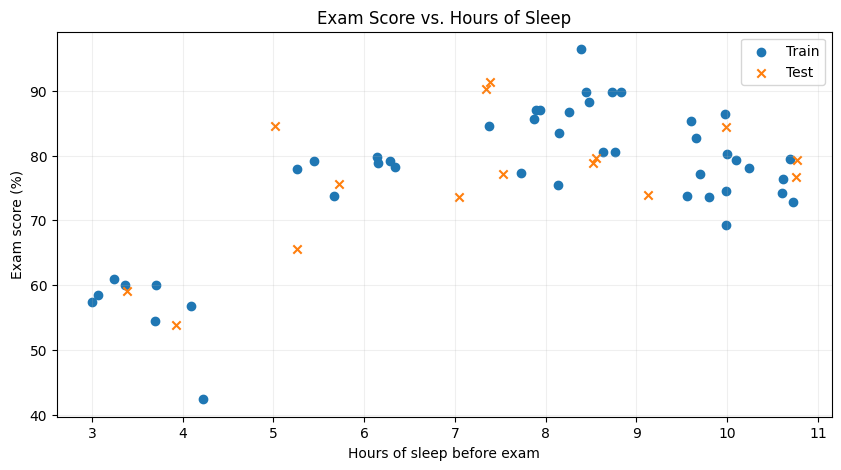

In [5]:
# Separate the rows only for visualization
train_df = df[df["split"] == "train"]
test_df = df[df["split"] == "test"]

plt.figure(figsize=(10, 5))

# Use different markers for train and test data
plt.scatter(
    train_df["Hours_of_Sleep"],
    train_df["Exam_Score"],
    label="Train",
    marker="o"
)

plt.scatter(
    test_df["Hours_of_Sleep"],
    test_df["Exam_Score"],
    label="Test",
    marker="x"
)

plt.xlabel("Hours of sleep before exam")
plt.ylabel("Exam score (%)")
plt.title("Exam Score vs. Hours of Sleep")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 4. Prepare X and y

We will use the split already included in the CSV instead of creating a new random split.

- `X_train` and `y_train` are used to fit the model.
- `X_test` and `y_test` are used to evaluate the model.


In [6]:
# Create training data
X_train = train_df[["Hours_of_Sleep"]]
y_train = train_df["Exam_Score"]

# Create test data
X_test = test_df[["Hours_of_Sleep"]]
y_test = test_df["Exam_Score"]

# Create the complete X and y arrays for the 5-fold CV section
X = df[["Hours_of_Sleep"]]
y = df["Exam_Score"]

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 45
Test observations: 15


## 5. Baseline Decision Tree Model

The exercise code uses:

```python
max_depth = 2
min_samples_leaf = 4
```

We start with the same settings.

`max_depth = 2` allows the tree to create up to two levels of decisions.


In [7]:
# Create the baseline Decision Tree Regressor
max_depth = 2
min_samples_leaf = 4

model = DecisionTreeRegressor(
    max_depth=max_depth,
    min_samples_leaf=min_samples_leaf,
    random_state=0
)

# Train the model
model.fit(X_train, y_train)

print("Number of leaves:", model.get_n_leaves())

# Print the if/else rules learned by the tree
print("\nDecision Tree rules:")
print(export_text(
    model,
    feature_names=["Hours_of_Sleep"],
    decimals=2
))

Number of leaves: 4

Decision Tree rules:
|--- Hours_of_Sleep <= 4.74
|   |--- Hours_of_Sleep <= 3.53
|   |   |--- value: [59.22]
|   |--- Hours_of_Sleep >  3.53
|   |   |--- value: [53.41]
|--- Hours_of_Sleep >  4.74
|   |--- Hours_of_Sleep <= 9.68
|   |   |--- value: [82.83]
|   |--- Hours_of_Sleep >  9.68
|   |   |--- value: [76.81]



## 6. Evaluate the Baseline Model

We use three main measurements:

### Mean Squared Error (MSE)
Measures the average squared prediction error.

- **Lower MSE is better.**
- A high Test MSE can indicate poor generalization.

### R²
Measures how much of the variation in exam score is explained by the model.

- `R² = 1` means a perfect fit.
- Values closer to 1 are generally better.

### Train vs. Test
Comparing training and test performance helps us identify possible **overfitting**.


In [8]:
# Make predictions
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Calculate evaluation metrics
train_mse = mean_squared_error(y_train, train_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

print(f"Train MSE: {train_mse:.3f}")
print(f"Test MSE:  {test_mse:.3f}")
print(f"Test R²:   {test_r2:.3f}")

Train MSE: 26.245
Test MSE:  51.336
Test R²:   0.490


## 7. What Does 5-Fold Cross-Validation Mean?

**5-Fold Cross-Validation** divides the dataset into 5 groups called **folds**.

The model is trained and validated 5 times:

```text
Run 1: Test Fold 1 | Train Folds 2, 3, 4, 5
Run 2: Test Fold 2 | Train Folds 1, 3, 4, 5
Run 3: Test Fold 3 | Train Folds 1, 2, 4, 5
Run 4: Test Fold 4 | Train Folds 1, 2, 3, 5
Run 5: Test Fold 5 | Train Folds 1, 2, 3, 4
```

Every observation is used for validation once.

This gives us a more complete idea of how the model performs on different subsets of the data instead of relying on only one train/test split.

The supplied exercise uses **5-Fold CV MSE**, so we reproduce it below.


In [9]:
# Create 5 folds.
# shuffle=True mixes the observations before creating the folds.
# random_state=0 makes the result reproducible.
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# scikit-learn returns negative MSE for this scorer,
# so we multiply by -1 to obtain normal positive MSE values.
cv_scores = -cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="neg_mean_squared_error"
)

# Show the MSE from each fold
fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MSE": cv_scores
})

display(fold_results)

print(f"5-Fold CV Mean MSE: {cv_scores.mean():.3f}")
print(f"5-Fold CV MSE Std:  {cv_scores.std():.3f}")

,Fold,MSE
0,1,60.955
1,2,39.180
2,3,39.155
3,4,27.375
4,5,40.393


5-Fold CV Mean MSE: 41.412
5-Fold CV MSE Std:  10.864


### How to interpret the folds

The five MSE values will not be exactly the same because each fold contains different observations.

The **mean CV MSE** summarizes the average validation error.

The **standard deviation** shows how much the result changes between folds. A smaller variation usually means that the model is more stable across different subsets.


## 8. Required Exploration: Set `max_depth = 1`

The exercise asks:

> **Set `max_depth = 1`. The single split is the most important threshold in the data. Where is it?**

With `max_depth = 1`, the Decision Tree can make only **one split**.

This makes it easy to identify the most important threshold learned from the training data.


In [10]:
# Create a Decision Tree with only one split
depth_1_model = DecisionTreeRegressor(
    max_depth=1,
    min_samples_leaf=4,
    random_state=0
)

# Train the model
depth_1_model.fit(X_train, y_train)

# Print the learned rule
print(export_text(
    depth_1_model,
    feature_names=["Hours_of_Sleep"],
    decimals=3
))

# The first threshold is stored in tree_.threshold[0]
important_threshold = depth_1_model.tree_.threshold[0]

print(f"Most important threshold: {important_threshold:.3f} hours")

|--- Hours_of_Sleep <= 4.743
|   |--- value: [56.317]
|--- Hours_of_Sleep >  4.743
|   |--- value: [80.880]

Most important threshold: 4.743 hours


### Interpretation of the Main Threshold

The tree automatically finds the point that best separates the exam scores in the training data.

For this dataset, the split should appear close to the **5-hour** idea described in the use case.

Students below this threshold tend to have lower scores, while observations above it tend to have higher scores.

The exact threshold is calculated by the model rather than selected manually.


In [11]:
# Calculate the average exam score on each side of the first split
left_group = train_df[
    train_df["Hours_of_Sleep"] <= important_threshold
]["Exam_Score"]

right_group = train_df[
    train_df["Hours_of_Sleep"] > important_threshold
]["Exam_Score"]

print(f"Students at or below {important_threshold:.3f} hours:")
print(f"  Observations: {len(left_group)}")
print(f"  Average exam score: {left_group.mean():.2f}%")

print(f"\nStudents above {important_threshold:.3f} hours:")
print(f"  Observations: {len(right_group)}")
print(f"  Average exam score: {right_group.mean():.2f}%")

Students at or below 4.743 hours:
  Observations: 8
  Average exam score: 56.32%

Students above 4.743 hours:
  Observations: 37
  Average exam score: 80.88%


## 9. Visualize the One-Split Tree

This diagram shows the single decision made by the tree.


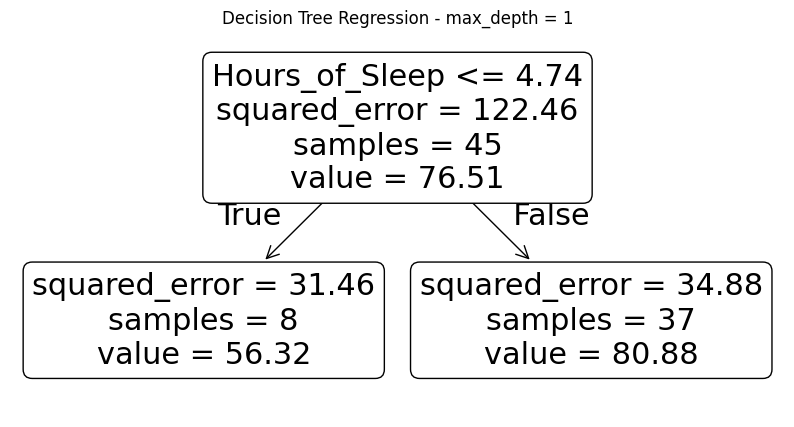

In [12]:
plt.figure(figsize=(10, 5))

plot_tree(
    depth_1_model,
    feature_names=["Hours_of_Sleep"],
    filled=False,
    rounded=True,
    precision=2
)

plt.title("Decision Tree Regression - max_depth = 1")
plt.show()

## 10. Visualize the Regression Prediction

A Decision Tree does not create a smooth line. It creates **step-like predictions** because each leaf predicts a constant value for a range of inputs.


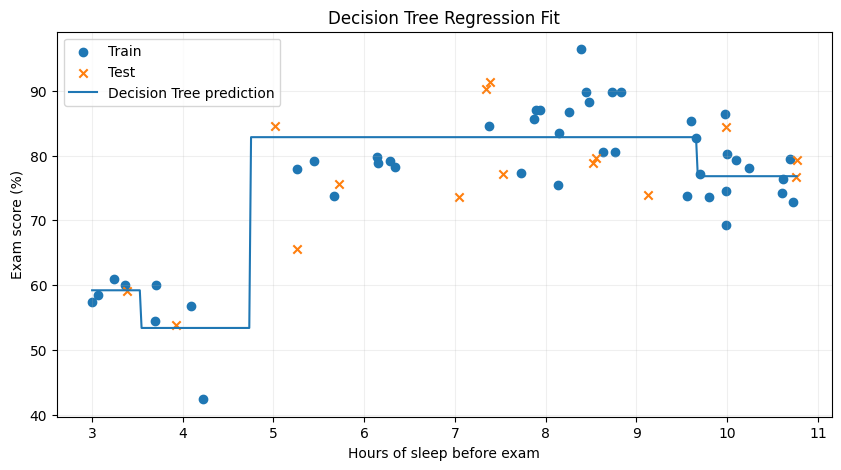

In [13]:
# Create many sleep-hour values so that we can draw the prediction line
X_grid = pd.DataFrame({
    "Hours_of_Sleep": np.linspace(
        df["Hours_of_Sleep"].min(),
        df["Hours_of_Sleep"].max(),
        400
    )
})

plt.figure(figsize=(10, 5))

plt.scatter(
    X_train["Hours_of_Sleep"],
    y_train,
    label="Train",
    marker="o"
)

plt.scatter(
    X_test["Hours_of_Sleep"],
    y_test,
    label="Test",
    marker="x"
)

# Plot the baseline Decision Tree predictions
plt.plot(
    X_grid["Hours_of_Sleep"],
    model.predict(X_grid),
    label="Decision Tree prediction"
)

plt.xlabel("Hours of sleep before exam")
plt.ylabel("Exam score (%)")
plt.title("Decision Tree Regression Fit")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 11. Compare Different Values of `max_depth`

Now we test multiple tree depths.

For each depth, we calculate:

- Train MSE
- Test MSE
- Test R²
- 5-Fold CV Mean MSE
- Number of leaves

This helps us see how model complexity changes performance.


In [14]:
# Compare several tree depths
results = []

for depth in range(1, 7):
    # Create a model with the current depth
    depth_model = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=4,
        random_state=0
    )

    # Train using the supplied training split
    depth_model.fit(X_train, y_train)

    # Predictions for train and test
    y_train_pred = depth_model.predict(X_train)
    y_test_pred = depth_model.predict(X_test)

    # Evaluation on train/test
    current_train_mse = mean_squared_error(y_train, y_train_pred)
    current_test_mse = mean_squared_error(y_test, y_test_pred)
    current_test_r2 = r2_score(y_test, y_test_pred)

    # 5-Fold Cross-Validation using the same setup as the exercise
    current_cv_scores = -cross_val_score(
        depth_model,
        X,
        y,
        cv=KFold(n_splits=5, shuffle=True, random_state=0),
        scoring="neg_mean_squared_error"
    )

    # Store the results
    results.append({
        "max_depth": depth,
        "leaves": depth_model.get_n_leaves(),
        "Train_MSE": current_train_mse,
        "Test_MSE": current_test_mse,
        "Test_R2": current_test_r2,
        "CV_MSE_Mean": current_cv_scores.mean(),
        "CV_MSE_Std": current_cv_scores.std()
    })

results_df = pd.DataFrame(results)
results_df

,max_depth,leaves,Train_MSE,Test_MSE,Test_R2,CV_MSE_Mean,CV_MSE_Std
0,1,2,34.268,42.742,0.576,38.793,16.170
1,2,4,26.245,51.336,0.490,41.412,10.864
2,3,6,20.881,52.307,0.481,33.038,9.154
3,4,9,19.437,48.104,0.522,35.119,8.966
4,5,10,17.991,52.995,0.474,33.197,8.773
5,6,10,17.991,52.995,0.474,34.490,9.300


## 12. Plot Model Complexity vs. Error

This graph makes it easier to see the difference between training, test, and cross-validation error.

A common pattern is:

- As depth increases, **training error decreases**.
- Test/CV error may improve at first.
- If the tree becomes too complex, test/CV error can stop improving or increase.

That is one way to detect possible **overfitting**.


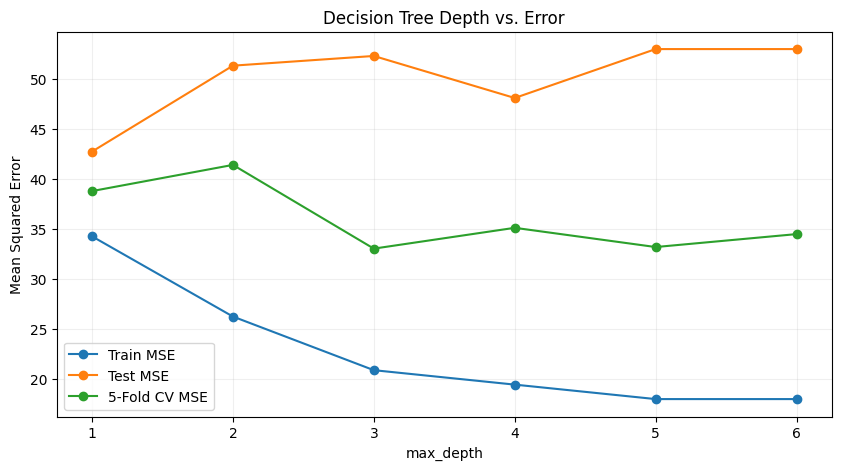

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["max_depth"],
    results_df["Train_MSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    results_df["max_depth"],
    results_df["Test_MSE"],
    marker="o",
    label="Test MSE"
)

plt.plot(
    results_df["max_depth"],
    results_df["CV_MSE_Mean"],
    marker="o",
    label="5-Fold CV MSE"
)

plt.xlabel("max_depth")
plt.ylabel("Mean Squared Error")
plt.title("Decision Tree Depth vs. Error")
plt.xticks(results_df["max_depth"])
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 13. Identify the Best Depth in This Experiment

There is not always one metric that tells the entire story.

For this exercise:

- **Train MSE** tells us how closely the model fits the training data.
- **Test MSE** measures performance on the supplied test set.
- **5-Fold CV MSE** measures performance across several validation subsets.

We can identify the lowest result for each evaluation method.


In [16]:
# Find the depth with the lowest Test MSE
best_test_row = results_df.loc[results_df["Test_MSE"].idxmin()]

# Find the depth with the lowest average Cross-Validation MSE
best_cv_row = results_df.loc[results_df["CV_MSE_Mean"].idxmin()]

print(
    f"Lowest Test MSE: max_depth = {int(best_test_row['max_depth'])}, "
    f"MSE = {best_test_row['Test_MSE']:.3f}"
)

print(
    f"Lowest 5-Fold CV MSE: max_depth = {int(best_cv_row['max_depth'])}, "
    f"MSE = {best_cv_row['CV_MSE_Mean']:.3f}"
)

Lowest Test MSE: max_depth = 1, MSE = 42.742
Lowest 5-Fold CV MSE: max_depth = 3, MSE = 33.038


### Why can Test MSE and 5-Fold CV choose different depths?

This dataset is small, so a single 25% test split contains only a limited number of observations.

5-Fold Cross-Validation evaluates the model on several different validation groups. Because of this, the best depth according to CV may be different from the best depth according to the single test set.

The important point is to compare the results instead of judging the model using only its training error.


## 14. Make an Example Prediction

The model can also predict an exam score for a new sleep value.

The example below uses the original baseline tree (`max_depth = 2`).


In [17]:
# Example: predict the exam score for a student who slept 7 hours
new_hours = 7

new_student = pd.DataFrame({
    "Hours_of_Sleep": [new_hours]
})

predicted_score = model.predict(new_student)[0]

print(f"Hours of sleep: {new_hours}")
print(f"Predicted exam score: {predicted_score:.2f}%")

Hours of sleep: 7
Predicted exam score: 82.83%


## 15. Final Conclusion

In this lab, we used a **Decision Tree Regressor** to predict exam scores from hours of sleep.

The main findings are:

1. A Decision Tree predicts numerical values by creating threshold-based `if/else` rules.
2. With `max_depth = 1`, the model finds the **single most important sleep-hour threshold**.
3. The threshold is close to the use-case idea that scores change noticeably around five hours of sleep.
4. Increasing `max_depth` creates a more complex tree and usually reduces training error.
5. A lower training error does **not automatically mean a better model**, because a complex tree can overfit.
6. **5-Fold Cross-Validation** evaluates the model five times using different validation subsets and gives a more complete view of model performance.
7. Comparing Train MSE, Test MSE, Test R², and 5-Fold CV MSE helps us understand whether the model generalizes beyond the training data.

### Student-Level Summary

The Decision Tree is useful for this use case because the relationship can contain clear cut-off points instead of following one smooth straight line. The tree can convert these patterns into readable decisions, such as separating students who slept below a certain number of hours from those who slept more.


## Deliverable Checklist

This notebook includes:

- [x] Explanation of Decision Tree Regression
- [x] Selected use case: Exam Score vs. Hours of Sleep
- [x] Dataset loading and inspection
- [x] Train/test data
- [x] Decision Tree training
- [x] MSE and R² evaluation
- [x] 5-Fold Cross-Validation
- [x] `max_depth = 1` threshold exploration
- [x] Decision Tree visualization
- [x] Comparison of multiple tree depths
- [x] Underfitting/overfitting discussion
- [x] Final conclusion
